# DiT-IC: запуск, тестирование и сравнение с JPEG / WebP

Ноутбук демонстрирует полный цикл работы с моделью **DiT-IC** (CVPR 2026):

1. проверка окружения и структуры проекта;
2. загрузка официального чекпоинта `q3_merge_ema.pt`;
3. сжатие и восстановление одного изображения;
4. прогон на датасете **Kodak** (24 изображения);
5. сравнение с классическими кодеками **JPEG** и **WebP** при одинаковом битрейте;
6. rate-distortion кривые и визуальное сравнение.

Исходники `DiT-IC/` не изменяются: все артефакты пишутся в `src/result`.

In [1]:
import json
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from PIL import Image

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "DiT-IC").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
SRC = PROJECT_ROOT / "src"
METRICS = SRC / "result" / "metrics"
FIGURES = SRC / "result" / "figures"
PY = sys.executable

print("project:", PROJECT_ROOT)
print("python :", sys.version.split()[0])
print("torch  :", torch.__version__, "| CUDA:", torch.version.cuda)
print("gpu    :", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

project: D:\Учеба\CV-labs\Deep-Image-Compression
python : 3.12.16
torch  : 2.8.0+cu128 | CUDA: 12.8
gpu    : NVIDIA GeForce RTX 5060 Ti


## 1. Структура проекта

Все результаты экспериментов находятся в `src/result`, веса и конфиги — в `src/models`.

In [2]:
for folder in ["models/checkpoints", "models/sana", "images/kodak", "result", "experiments", "scripts"]:
    path = SRC / folder
    n_files = sum(1 for p in path.rglob("*") if p.is_file()) if path.exists() else 0
    print(f"{folder:22s} {n_files:4d} files")

ckpt = SRC / "models" / "checkpoints" / "q3_merge_ema.pt"
print(f"\ncheckpoint: {ckpt.name}, {ckpt.stat().st_size / 1e9:.2f} GB")

models/checkpoints        1 files
models/sana               3 files
images/kodak             24 files
result                 2848 files
experiments               1 files
scripts                   7 files

checkpoint: q3_merge_ema.pt, 4.28 GB


## 2. Запуск DiT-IC на одном изображении

Используется merged-чекпоинт (`use_merge=True`): LoRA-веса уже влиты в базовую модель,
поэтому загрузка и инференс быстрее. Скрипт вызывает штатные `Codec.compress` / `Codec.decompress`
из `DiT-IC`, сохраняет реальный битстрим и считает BPP по его размеру.

In [3]:
cmd = [PY, str(SRC / "scripts" / "run_dit_ic.py"), "--limit", "2", "--no-rec"]
result = subprocess.run(cmd, cwd=PROJECT_ROOT, capture_output=True, text=True)
print(result.stdout[-4000:])
if result.returncode != 0:
    print(result.stderr[-4000:])
result.check_returncode()

[env] project root : D:\Учеба\CV-labs\Deep-Image-Compression
[env] python       : 3.12.16
[env] torch        : 2.8.0+cu128 (cuda 12.8)
[env] device       : NVIDIA GeForce RTX 5060 Ti
[model] checkpoint : D:\Учеба\CV-labs\Deep-Image-Compression\src\models\checkpoints\q3_merge_ema.pt
[model] sana       : D:\Учеба\CV-labs\Deep-Image-Compression\src\models\sana
========mode is #scale#======
Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]
Loading model from: D:\Учеба\CV-labs\Deep-Image-Compression\.venv\Lib\site-packages\lpips\weights\v0.1\alex.pth
Loading pretrained model DISTS from D:\Учеба\CV-labs\Deep-Image-Compression\src\models\cache\torch\hub\pyiqa\DISTS_weights-f5e65c96.pth
Using pp_style for nll loss
Init Done
[model] loaded in 8.3s, parameters: 1.069B
Loading pretrained model DISTS from D:\Учеба\CV-labs\Deep-Image-Compression\src\models\cache\torch\hub\pyiqa\DISTS_weights-f5e65c96.pth
Loading pretrained model MUSIQ from D:\Учеба\CV-labs\Deep-Image-Compressi

In [4]:
df_one = pd.read_csv(METRICS / "dit_ic_q3.csv")
df_one[["image", "bpp", "psnr", "ms_ssim", "lpips", "dists", "encode_ms", "decode_ms"]].round(4)

,image,bpp,psnr,ms_ssim,lpips,dists,encode_ms,decode_ms
0,kodim01,0.0880,21.7287,0.8276,0.1217,0.0608,2236.2911,1920.7726
1,kodim02,0.0769,27.5186,0.8910,0.0864,0.0633,277.8765,438.1485


## 3. Полный прогон на Kodak

Kodak — 24 изображения 768×512, стандартный benchmark для neural compression.
Для каждого изображения сохраняются битстрим и реконструкция; метрики усредняются.

In [5]:
cmd = [PY, str(SRC / "scripts" / "run_dit_ic.py")]
result = subprocess.run(cmd, cwd=PROJECT_ROOT, capture_output=True, text=True)
print(result.stdout[-5000:])
if result.returncode != 0:
    print(result.stderr[-5000:])
result.check_returncode()

[env] project root : D:\Учеба\CV-labs\Deep-Image-Compression
[env] python       : 3.12.16
[env] torch        : 2.8.0+cu128 (cuda 12.8)
[env] device       : NVIDIA GeForce RTX 5060 Ti
[model] checkpoint : D:\Учеба\CV-labs\Deep-Image-Compression\src\models\checkpoints\q3_merge_ema.pt
[model] sana       : D:\Учеба\CV-labs\Deep-Image-Compression\src\models\sana
========mode is #scale#======
Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]
Loading model from: D:\Учеба\CV-labs\Deep-Image-Compression\.venv\Lib\site-packages\lpips\weights\v0.1\alex.pth
Loading pretrained model DISTS from D:\Учеба\CV-labs\Deep-Image-Compression\src\models\cache\torch\hub\pyiqa\DISTS_weights-f5e65c96.pth
Using pp_style for nll loss
Init Done
[model] loaded in 8.2s, parameters: 1.069B
Loading pretrained model DISTS from D:\Учеба\CV-labs\Deep-Image-Compression\src\models\cache\torch\hub\pyiqa\DISTS_weights-f5e65c96.pth
Loading pretrained model MUSIQ from D:\Учеба\CV-labs\Deep-Image-Compressi

In [6]:
df_dit = pd.read_csv(METRICS / "dit_ic_q3.csv")
summary = json.loads((METRICS / "dit_ic_q3_summary.json").read_text())

avg = df_dit[["bpp", "psnr", "ms_ssim", "lpips", "dists", "clipiqa", "musiq", "encode_ms", "decode_ms"]].mean()
print(f"images: {summary['images']} | parameters: {summary['parameters_b']:.3f}B | peak VRAM: {summary['peak_vram_gb']:.2f} GB")
print(f"median encode: {summary['median_encode_ms']:.0f} ms | median decode: {summary['median_decode_ms']:.0f} ms")
display(avg.to_frame("average").round(4))
df_dit[["image", "bpp", "psnr", "lpips", "dists"]].round(4).head(10)

images: 24 | parameters: 1.069B | peak VRAM: 6.07 GB
median encode: 278 ms | median decode: 392 ms


,average
bpp,0.0805
psnr,24.2451
ms_ssim,0.8708
lpips,0.0911
dists,0.0554
clipiqa,0.7419
musiq,74.3901
encode_ms,410.9311
decode_ms,466.9521


,image,bpp,psnr,lpips,dists
0,kodim01,0.0880,21.7287,0.1217,0.0608
1,kodim02,0.0769,27.5186,0.0864,0.0633
2,kodim03,0.0771,28.6039,0.0496,0.0443
3,kodim04,0.0793,26.7385,0.0747,0.0368
4,kodim05,0.0977,19.8325,0.1225,0.0621
5,kodim06,0.0740,22.0787,0.0940,0.0637
6,kodim07,0.0876,26.0676,0.0593,0.0479
7,kodim08,0.0953,19.0996,0.1143,0.0719
8,kodim09,0.0706,26.8157,0.0559,0.0430
9,kodim10,0.0826,26.6900,0.0642,0.0458


## 4. Пример реконструкции

Ниже — оригинал, результат DiT-IC и карта абсолютной разницы для одного изображения.

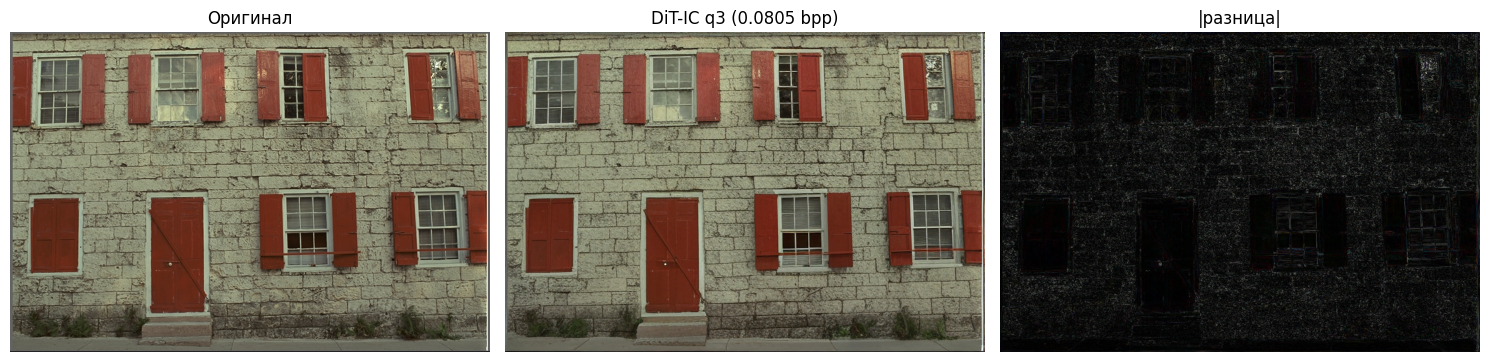

In [7]:
import numpy as np

name = "kodim01"
orig = Image.open(SRC / "images" / "kodak" / f"{name}.png").convert("RGB")
rec = Image.open(SRC / "result" / "kodak" / "q3" / "rec" / f"{name}.png").convert("RGB")
diff = np.abs(np.asarray(orig, dtype=np.int16) - np.asarray(rec, dtype=np.int16)).astype(np.uint8)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, image, title in zip(
    axes,
    [orig, rec, diff],
    ["Оригинал", f"DiT-IC q3 ({summary['avg_bpp']:.4f} bpp)", "|разница|"],
):
    ax.imshow(image, cmap="magma" if title.startswith("|") else None)
    ax.set_title(title)
    ax.axis("off")
fig.tight_layout()
plt.show()

## 5. Классические кодеки: JPEG и WebP

JPEG и WebP не умеют работать на ~0.08 BPP без потери разрешения, поэтому для них
используется сетка **(масштаб, качество)**: изображение уменьшается перед кодированием
и возвращается к исходному размеру после декодирования. BPP всегда считается по
исходному числу пикселей. Метрики — те же, что и для DiT-IC.

In [8]:
cmd = [PY, str(SRC / "scripts" / "run_baselines.py")]
result = subprocess.run(cmd, cwd=PROJECT_ROOT, capture_output=True, text=True)
print(result.stdout[-5000:])
if result.returncode != 0:
    print(result.stderr[-5000:])
result.check_returncode()

ed model DISTS from D:\Учеба\CV-labs\Deep-Image-Compression\src\models\cache\torch\hub\pyiqa\DISTS_weights-f5e65c96.pth
Loading pretrained model MUSIQ from D:\Учеба\CV-labs\Deep-Image-Compression\src\models\cache\torch\hub\pyiqa\musiq_koniq_ckpt-e95806b9.pth
jpeg s=0.25 q01: bpp 0.0235 | PSNR 19.135 | LPIPS 0.7978
jpeg s=0.25 q05: bpp 0.0278 | PSNR 20.664 | LPIPS 0.7861
jpeg s=0.25 q10: bpp 0.0365 | PSNR 22.089 | LPIPS 0.7730
jpeg s=0.25 q20: bpp 0.0512 | PSNR 23.084 | LPIPS 0.7303
jpeg s=0.25 q30: bpp 0.0632 | PSNR 23.540 | LPIPS 0.6987
jpeg s=0.25 q50: bpp 0.0829 | PSNR 24.015 | LPIPS 0.6584
jpeg s=0.25 q70: bpp 0.1092 | PSNR 24.435 | LPIPS 0.6198
jpeg s=0.25 q90: bpp 0.1934 | PSNR 25.068 | LPIPS 0.5616
jpeg s=0.35 q01: bpp 0.0348 | PSNR 19.711 | LPIPS 0.7470
jpeg s=0.35 q05: bpp 0.0426 | PSNR 21.374 | LPIPS 0.7128
jpeg s=0.35 q10: bpp 0.0587 | PSNR 22.981 | LPIPS 0.6715
jpeg s=0.35 q20: bpp 0.0862 | PSNR 24.133 | LPIPS 0.6126
jpeg s=0.35 q30: bpp 0.1092 | PSNR 24.677 | LPIPS 0.5764


In [9]:
df_base = pd.read_csv(METRICS / "baselines_kodak_summary.csv")
table = (
    df_base.groupby(["codec", "scale"])
    .agg(bpp_min=("bpp", "min"), bpp_max=("bpp", "max"),
         psnr_min=("psnr", "min"), psnr_max=("psnr", "max"),
         lpips_min=("lpips", "min"), lpips_max=("lpips", "max"))
    .round(4)
)
display(table)
df_base[["codec", "scale", "quality", "bpp", "psnr", "ms_ssim", "lpips", "dists"]].round(4).head(12)

bpp_min  bpp_max  psnr_min  psnr_max  lpips_min  lpips_max
codec scale                                                            
jpeg  0.25    0.0235   0.1934   19.1348   25.0677     0.5616     0.7978
      0.35    0.0348   0.3594   19.7106   26.5357     0.4403     0.7470
      0.50    0.0541   0.6666   20.2813   28.7292     0.2844     0.7060
      0.70    0.0951   1.2421   20.8969   31.9178     0.1261     0.6486
      1.00    0.1731   2.3463   21.4750   38.0337     0.0150     0.5799
webp  0.25    0.0165   0.1633   22.3182   25.2054     0.5368     0.7300
      0.35    0.0290   0.3034   23.2793   26.7050     0.4138     0.6517
      0.50    0.0511   0.5768   24.3948   28.9719     0.2627     0.5529
      0.70    0.0919   1.0654   25.6643   32.3051     0.1216     0.4516
      1.00    0.1653   2.0104   27.1850   39.5566     0.0194     0.3581

,codec,scale,quality,bpp,psnr,ms_ssim,lpips,dists
0,jpeg,0.25,1,0.0235,19.1348,0.5900,0.7978,0.4302
1,jpeg,0.25,5,0.0278,20.6640,0.6801,0.7861,0.3820
2,jpeg,0.25,10,0.0365,22.0889,0.7616,0.7730,0.3464
3,jpeg,0.25,20,0.0512,23.0839,0.8197,0.7303,0.3214
4,jpeg,0.25,30,0.0632,23.5402,0.8445,0.6987,0.3112
5,jpeg,0.25,50,0.0829,24.0147,0.8694,0.6584,0.2975
6,jpeg,0.25,70,0.1092,24.4347,0.8899,0.6198,0.2863
7,jpeg,0.25,90,0.1934,25.0677,0.9182,0.5616,0.2625
8,jpeg,0.35,1,0.0348,19.7106,0.6427,0.7470,0.4179
9,jpeg,0.35,5,0.0426,21.3738,0.7347,0.7128,0.3614


## 6. Rate-distortion кривые и сравнение при одинаковом BPP

Точка DiT-IC сравнивается с интерполированными значениями JPEG/WebP при том же BPP.

DiT-IC q3: 0.0805 bpp
Saved figures to D:\Учеба\CV-labs\Deep-Image-Compression\src\result\figures
Saved D:\Учеба\CV-labs\Deep-Image-Compression\src\result\metrics\matched_bpp.csv



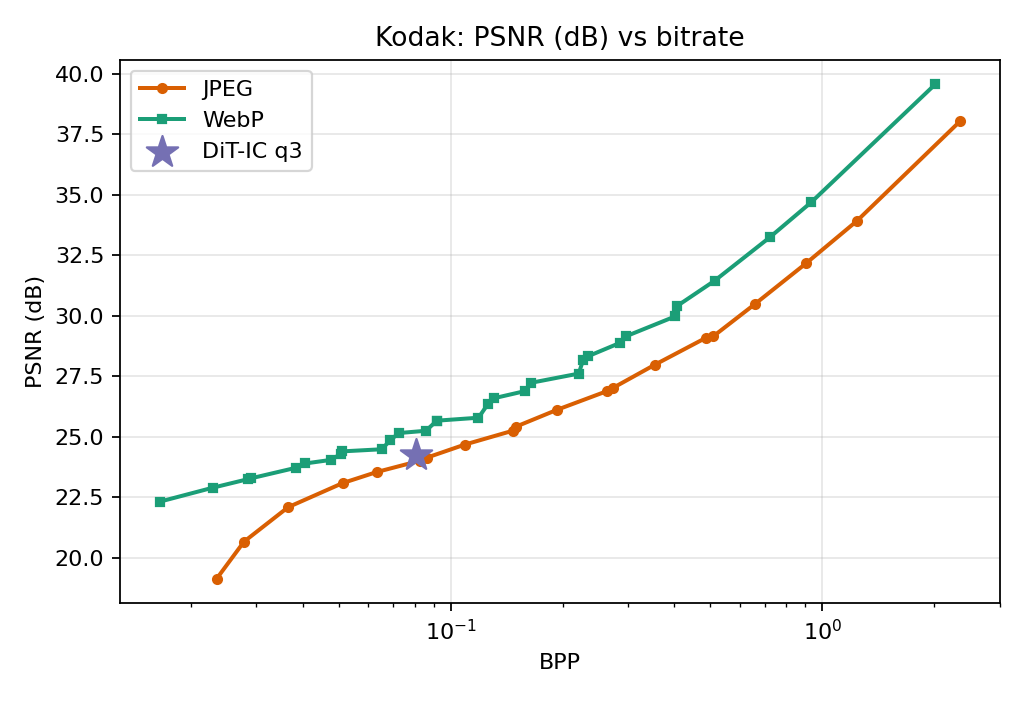

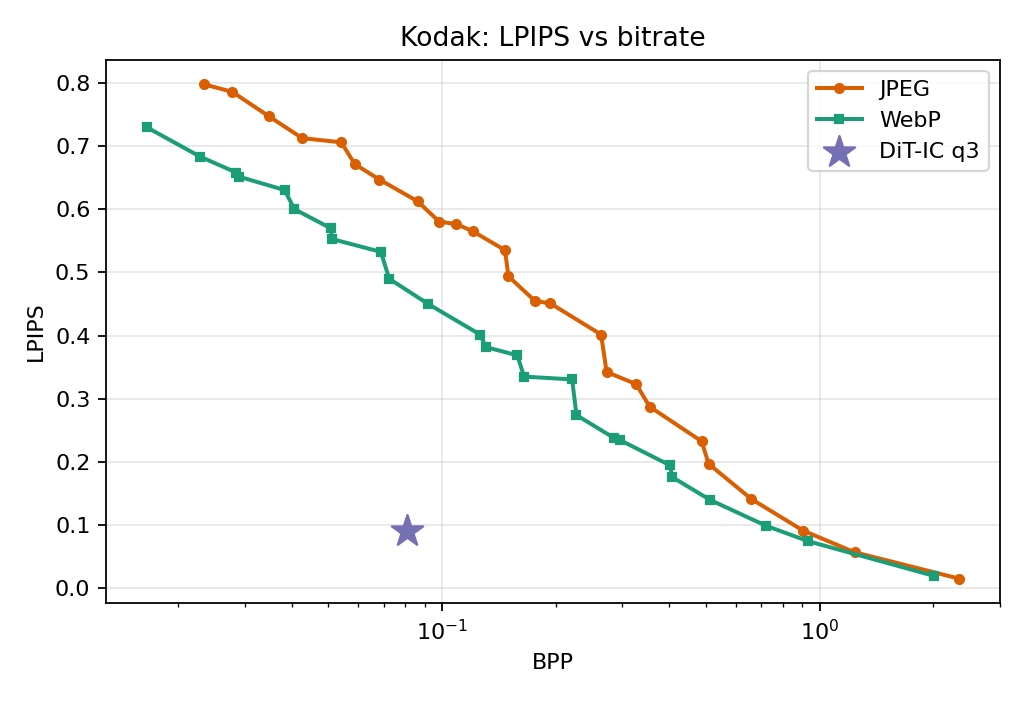

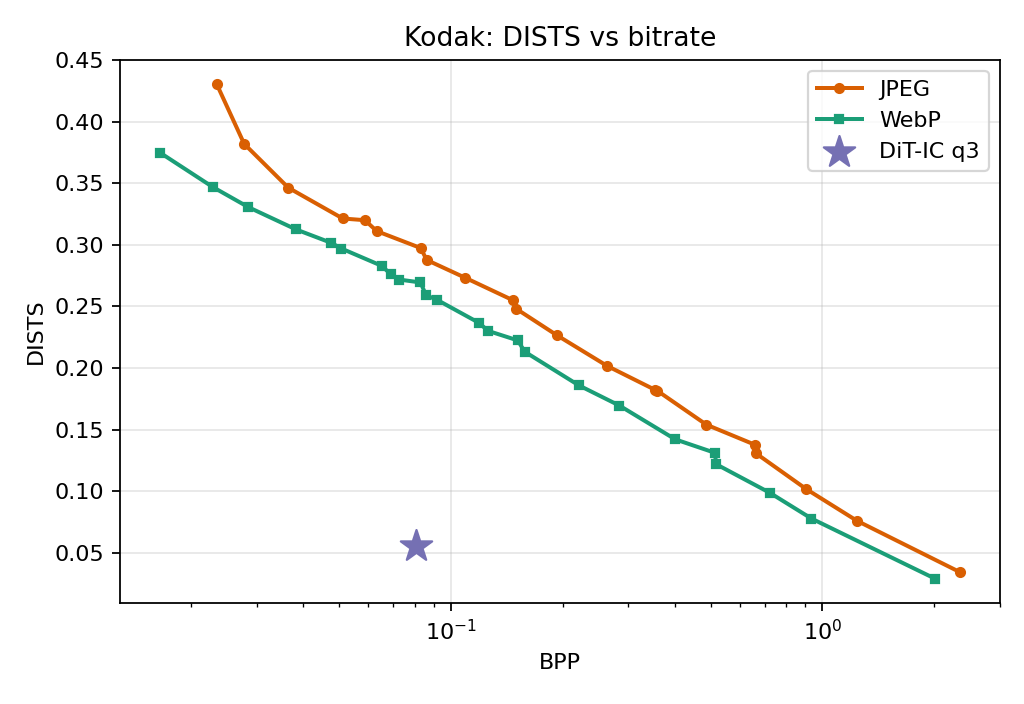

In [10]:
cmd = [PY, str(SRC / "scripts" / "make_plots.py")]
result = subprocess.run(cmd, cwd=PROJECT_ROOT, capture_output=True, text=True)
print(result.stdout)
if result.returncode != 0:
    print(result.stderr[-3000:])
result.check_returncode()

for name in ["rd_psnr", "rd_lpips", "rd_dists"]:
    display(Image.open(FIGURES / f"{name}.png"))

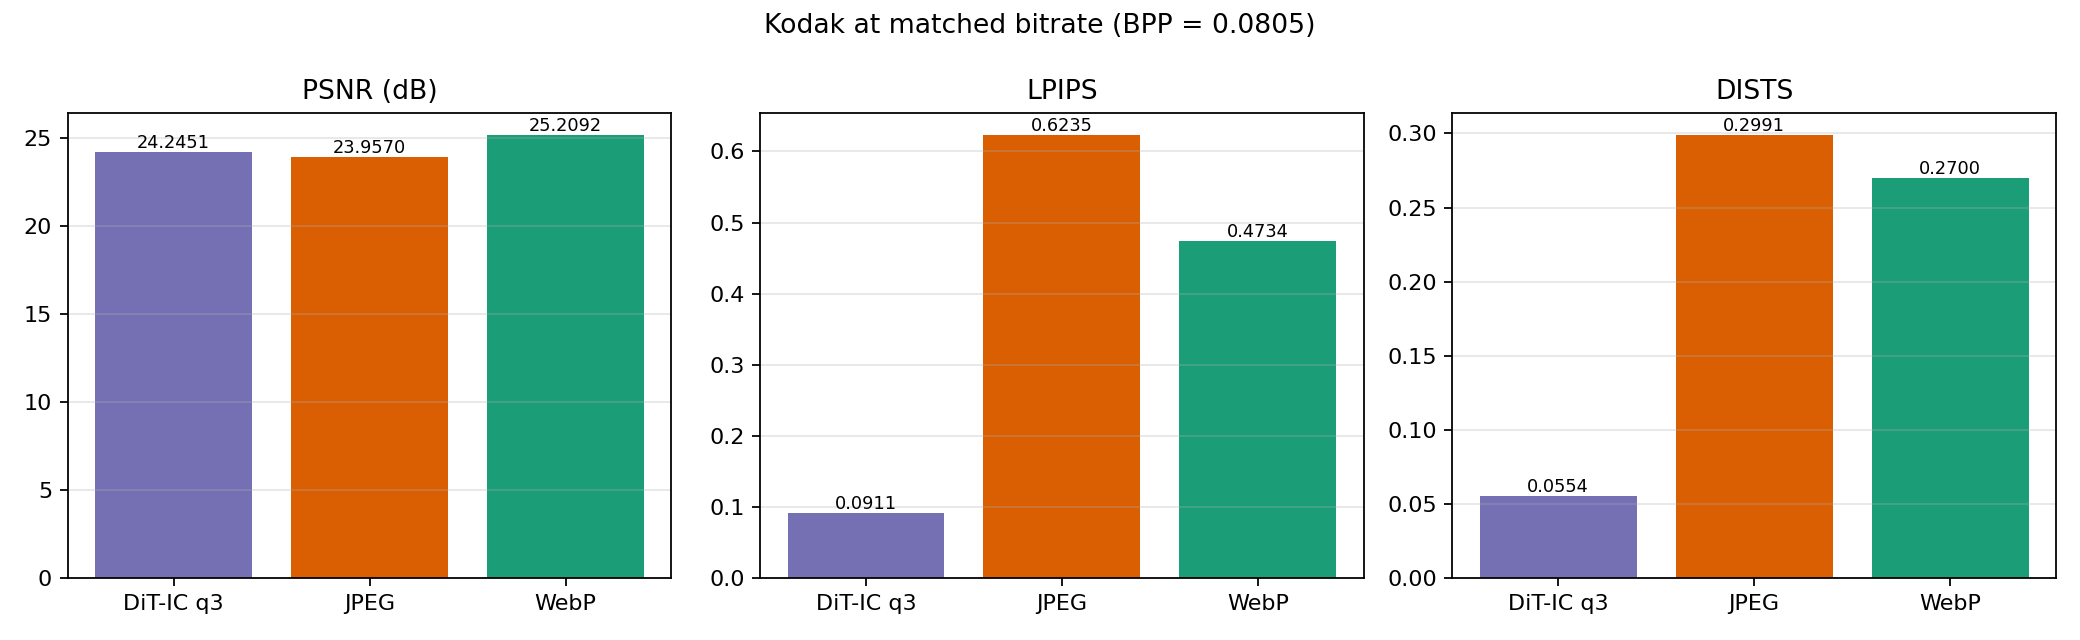

,codec,bpp,psnr,ms_ssim,lpips,dists,clipiqa,musiq
0,dit_ic_q3,0.0805,24.2451,0.8708,0.0911,0.0554,0.7419,74.3901
1,jpeg,0.0805,23.9570,0.8664,0.6235,0.2991,0.4055,29.1072
2,webp,0.0805,25.2092,0.8979,0.4734,0.2700,0.4711,46.8696


In [11]:
matched = pd.read_csv(METRICS / "matched_bpp.csv")
display(Image.open(FIGURES / "matched_bpp_bars.png"))
matched.round(4)

## 7. Визуальное сравнение

Фрагмент изображения при близком битрейте: DiT-IC, JPEG и WebP.

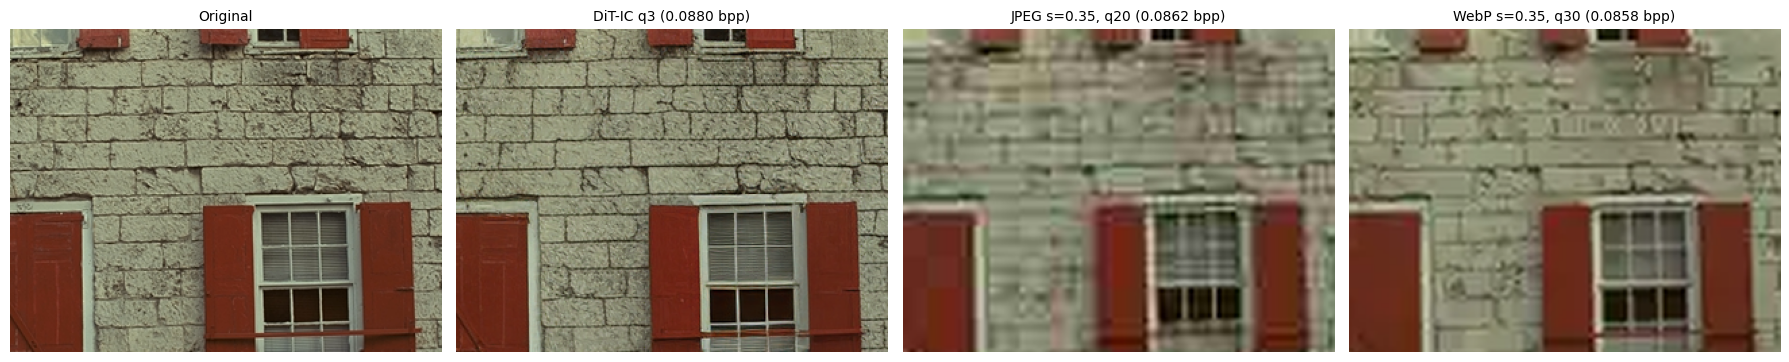

In [12]:
name = "kodim01"
orig = Image.open(SRC / "images" / "kodak" / f"{name}.png").convert("RGB")
dit_target = float(df_dit.loc[df_dit.image == name, "bpp"].iloc[0])

def nearest_row(codec):
    sub = df_base[df_base.codec == codec]
    return sub.iloc[(sub.bpp - dit_target).abs().argsort()[:1]].iloc[0]

def load_baseline(codec, row):
    ext = "jpg" if codec == "jpeg" else "webp"
    path = (
        SRC / "result" / "baselines" / "encoded" / codec
        / f"s{float(row.scale):g}" / f"q{int(row.quality):02d}" / f"{name}.{ext}"
    )
    image = Image.open(path).convert("RGB")
    if image.size != orig.size:
        image = image.resize(orig.size, Image.Resampling.LANCZOS)
    return image

row_jpeg = nearest_row("jpeg")
row_webp = nearest_row("webp")
images = {
    "Original": orig,
    f"DiT-IC q3 ({dit_target:.4f} bpp)": Image.open(SRC / "result" / "kodak" / "q3" / "rec" / f"{name}.png").convert("RGB"),
    f"JPEG s={float(row_jpeg.scale):g}, q{int(row_jpeg.quality)} ({float(row_jpeg.bpp):.4f} bpp)": load_baseline("jpeg", row_jpeg),
    f"WebP s={float(row_webp.scale):g}, q{int(row_webp.quality)} ({float(row_webp.bpp):.4f} bpp)": load_baseline("webp", row_webp),
}

w, h = orig.size
crop = (w // 3, h // 4, w // 3 + 320, h // 4 + 240)
fig, axes = plt.subplots(1, 4, figsize=(18, 4.4))
for ax, (title, img) in zip(axes, images.items()):
    ax.imshow(img.crop(crop))
    ax.set_title(title, fontsize=10)
    ax.axis("off")
fig.tight_layout()
plt.show()

## 8. Выводы

In [13]:
r = {row["codec"]: row for row in matched.to_dict("records")}
dit = r["dit_ic_q3"]

print(f"DiT-IC q3: {dit['bpp']:.4f} bpp | PSNR {dit['psnr']:.2f} dB | LPIPS {dit['lpips']:.4f} | DISTS {dit['dists']:.4f}")
for codec in ("jpeg", "webp"):
    row = r[codec]
    print(
        f"{codec.upper():4s} @ {row['bpp']:.4f} bpp | "
        f"PSNR {row['psnr']:.2f} dB ({row['psnr'] - dit['psnr']:+.2f}) | "
        f"LPIPS {row['lpips']:.4f} ({row['lpips'] - dit['lpips']:+.4f}) | "
        f"DISTS {row['dists']:.4f} ({row['dists'] - dit['dists']:+.4f})"
    )

print("\nВремя на изображение (медиана, после прогрева):")
print(f"encode: {summary['median_encode_ms']:.0f} ms | decode: {summary['median_decode_ms']:.0f} ms")

DiT-IC q3: 0.0805 bpp | PSNR 24.25 dB | LPIPS 0.0911 | DISTS 0.0554
JPEG @ 0.0805 bpp | PSNR 23.96 dB (-0.29) | LPIPS 0.6235 (+0.5324) | DISTS 0.2991 (+0.2437)
WEBP @ 0.0805 bpp | PSNR 25.21 dB (+0.96) | LPIPS 0.4734 (+0.3823) | DISTS 0.2700 (+0.2146)

Время на изображение (медиана, после прогрева):
encode: 278 ms | decode: 392 ms


**Интерпретация**

- DiT-IC работает в режиме экстремально низкого битрейта (~0.08 BPP), где классические JPEG/WebP
  уже теряют структуру изображения.
- По PSNR классические кодеки при том же BPP могут быть конкурентны, но перцептивные метрики
  (LPIPS, DISTS) и визуальное качество у DiT-IC заметно лучше — это и есть цель diffusion-based codec.
- Основная цена — скорость: один шаг DiT на GPU против миллисекунд у JPEG/WebP.